In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True})


df = pd.read_csv('PHA_cleaned_data.csv')
print(f"Dataset Loaded Successfully! Shape: {df.shape}")


numeric_features = [col for col in ['a', 'e', 'i', 'H', 'diameter', 'moid', 'per', 'om', 'w', 'ma'] if col in df.columns]
categorical_features = [col for col in ['neo', 'pha', 'class'] if col in df.columns]


In [ ]:
# ==========================================================
# 1. UNIVARIATE ANALYSIS (Distributions & Class Balance)
# ==========================================================
print("\n--- Generating Univariate Analysis Plots ---")


if len(numeric_features) > 0:
    fig, axes = plt.subplots(nrows=(len(numeric_features) + 2) // 3, ncols=3, figsize=(16, 4 * ((len(numeric_features) + 2) // 3)))
    axes = axes.flatten()
    
    for i, col in enumerate(numeric_features):
        sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color='royalblue', bins=50)
        axes[i].set_title(f'Distribution: {col}', fontsize=11)
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Count')
        

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
        
    plt.suptitle("Univariate Analysis: Numeric Features (Distribution & Skewness)", fontsize=14, y=1.02)
    plt.show()


if len(categorical_features) > 0:
    fig, axes = plt.subplots(nrows=1, ncols=len(categorical_features), figsize=(6 * len(categorical_features), 5))
    if len(categorical_features) == 1:
        axes = [axes]
        
    for i, col in enumerate(categorical_features):
        sns.countplot(x=df[col], ax=axes[i], palette='Set2')
        axes[i].set_title(f'Class Balance: {col}', fontsize=11)
        axes[i].set_xlabel(col)
        axes[i].set_ylabel('Frequency')
        
        for p in axes[i].patches:
            height = int(p.get_height())
            axes[i].annotate(f'{height:,}', 
                             (p.get_x() + p.get_width() / 2., p.get_height()), 
                             ha='center', va='bottom', fontsize=9, xytext=(0, 3), 
                             textcoords='offset points')
            
    plt.suptitle("Univariate Analysis: Categorical Features & Class Imbalance", fontsize=14, y=1.03)
    plt.show()


In [ ]:
# ==========================================================
# 2. SKEWNESS & OUTLIERS INSPECTION
# ==========================================================
print("\n--- Skewness Inspection for Numeric Features ---")
skewness_vals = df[numeric_features].skew().sort_values(ascending=False)
skew_df = pd.DataFrame({'Skewness': skewness_vals})
print(skew_df)

In [ ]:
# ==========================================================
# 3. CORRELATION HEATMAP (Multicollinearity Check)
# ==========================================================
print("\n--- Generating Correlation Heatmap ---")
plt.figure(figsize=(10, 8))
corr_matrix = df[numeric_features].corr()

# Draw heatmap
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, cbar_kws={'label': 'Pearson Correlation'})
plt.title("Correlation Heatmap of Numeric Features (Multicollinearity Check)", fontsize=14)
plt.show()

Dataset Loaded Successfully! Shape: (958524, 36)

--- Generating Univariate Analysis Plots ---


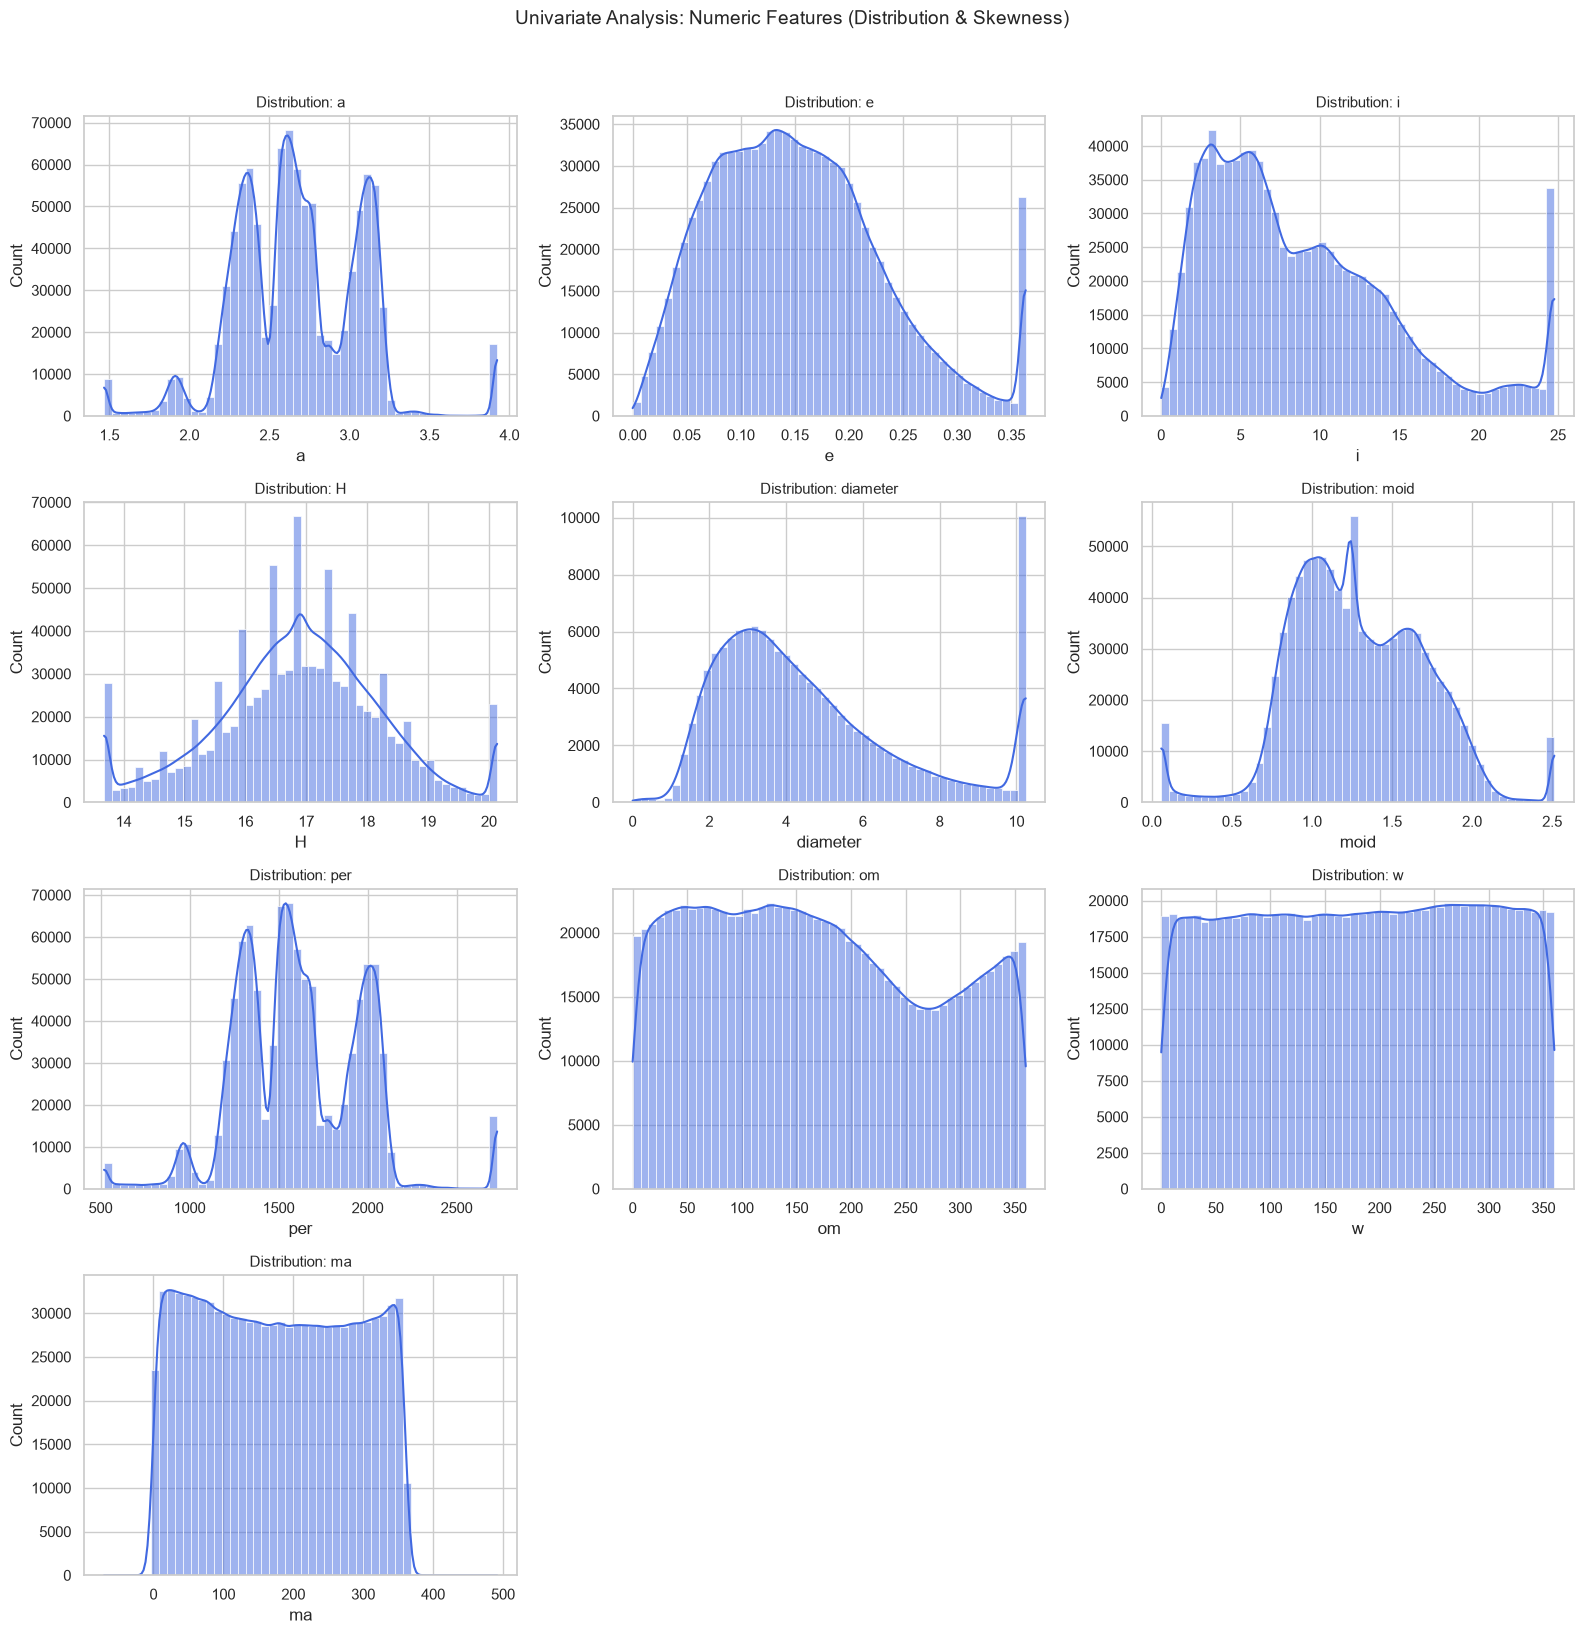

C:\Users\ponpriya\AppData\Local\Temp\ipykernel_6412\3274361977.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df[col], ax=axes[i], palette='Set2')
C:\Users\ponpriya\AppData\Local\Temp\ipykernel_6412\3274361977.py:49: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df[col], ax=axes[i], palette='Set2')


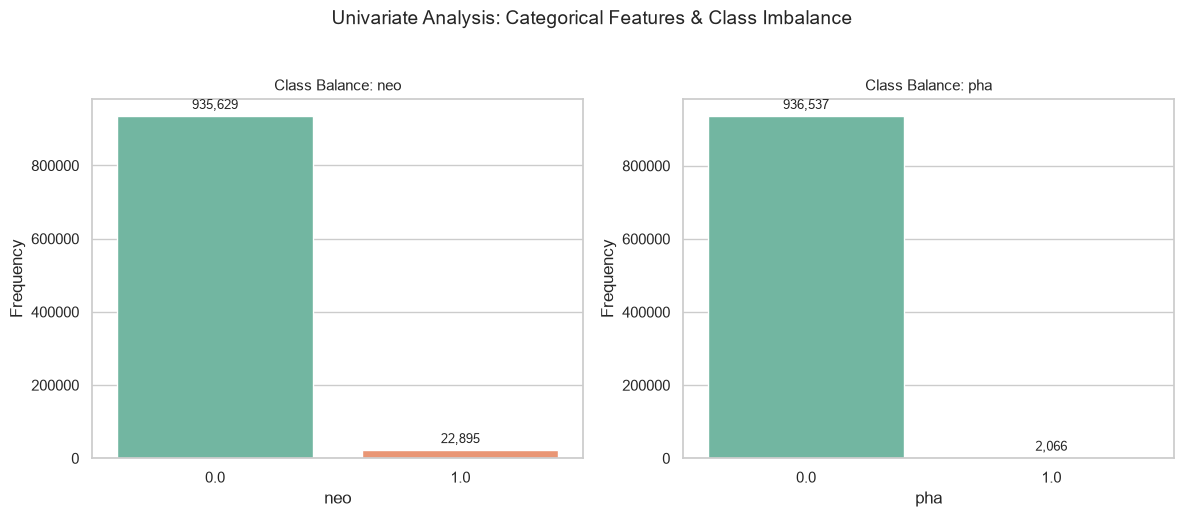


--- Skewness Inspection for Numeric Features ---
          Skewness
diameter  0.958134
i         0.937240
e         0.592488
per       0.283127
om        0.198256
a         0.168974
moid      0.047612
ma        0.040664
w        -0.020330
H        -0.089265

[Note]: High positive skewness indicates heavy right-tails (e.g., extreme orbital radii or diameters), which justify your log transformations!

--- Generating Correlation Heatmap ---


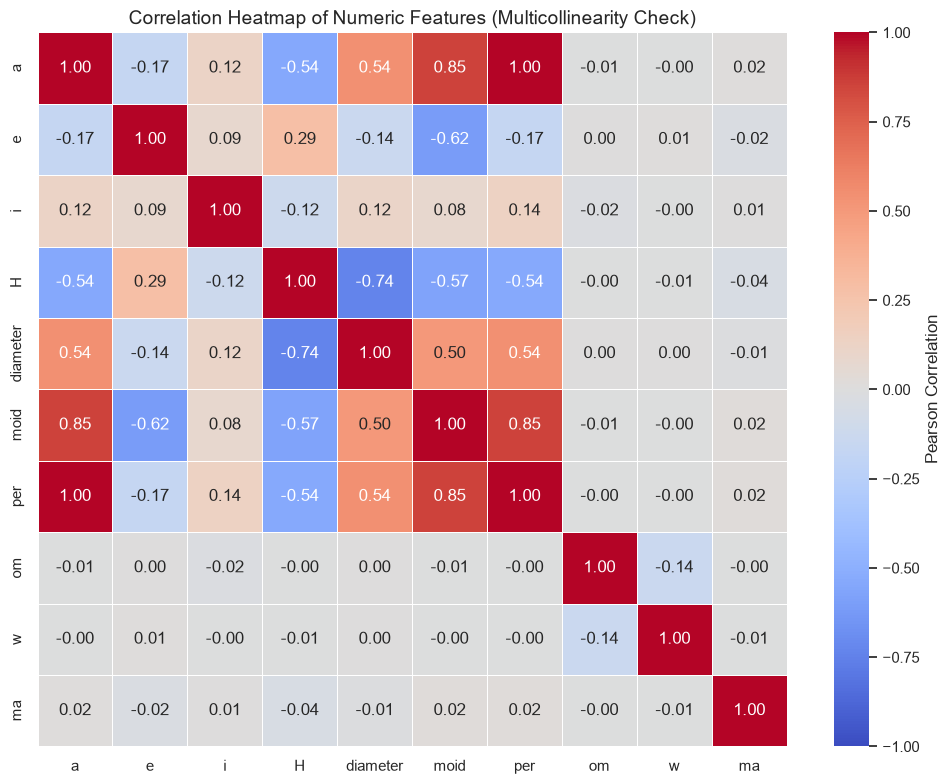


--- Generating Bivariate Analysis Plots ---


C:\Users\ponpriya\AppData\Local\Temp\ipykernel_6412\3274361977.py:96: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='pha', y='moid', data=df, palette='Set1')


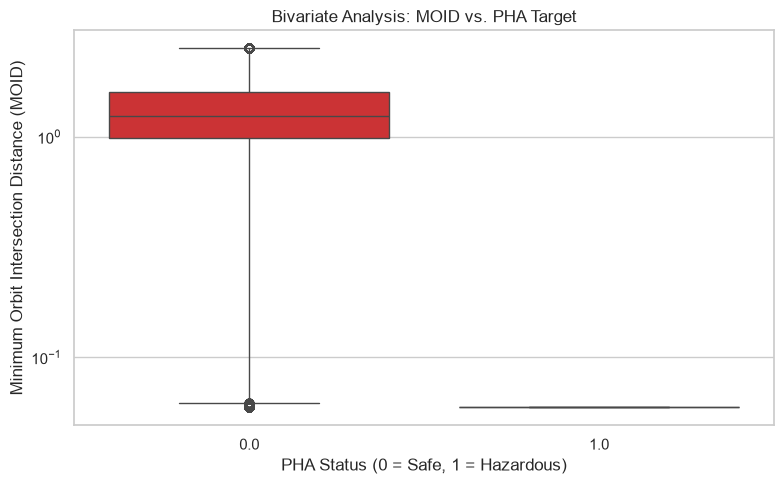

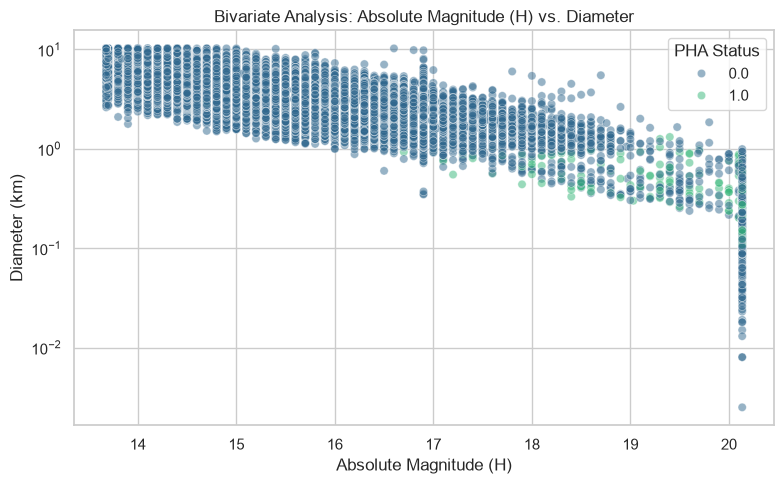

In [ ]:
# ==========================================================
# 4. BIVARIATE ANALYSIS (Signals, Patterns & Leakage Check)
# ==========================================================
print("\n--- Generating Bivariate Analysis Plots ---")

if 'moid' in df.columns and 'pha' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(x='pha', y='moid', data=df, palette='Set1')
    plt.title("Bivariate Analysis: MOID vs. PHA Target", fontsize=12)
    plt.xlabel("PHA Status (0 = Safe, 1 = Hazardous)")
    plt.ylabel("Minimum Orbit Intersection Distance (MOID)")
    plt.yscale('log')
    plt.show()

if 'H' in df.columns and 'diameter' in df.columns:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(x='H', y='diameter', hue='pha', data=df, alpha=0.5, palette='viridis')
    plt.title("Bivariate Analysis: Absolute Magnitude (H) vs. Diameter", fontsize=12)
    plt.xlabel("Absolute Magnitude (H)")
    plt.ylabel("Diameter (km)")
    plt.yscale('log')
    plt.legend(title='PHA Status')
    plt.show()